Observations (train): 307,511
Observations (test):  48,744
Variables:            122
Missing values:       9,152,465 (24.4% of all cells)
Duplicates:           0
Numeric features:     104
Categorical features: 16


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE
245895,384575,0,Cash loans,M,Y,N,2,207000.0,465457.5,52641.0,418500.0,Unaccompanied
98194,214010,0,Cash loans,F,Y,Y,0,247500.0,1281712.5,48946.5,1179000.0,Unaccompanied
36463,142232,0,Cash loans,F,Y,N,0,202500.0,495000.0,39109.5,495000.0,Unaccompanied
249923,389171,0,Cash loans,F,N,Y,0,247500.0,254700.0,24939.0,225000.0,Unaccompanied
158389,283617,0,Cash loans,M,N,Y,0,112500.0,308133.0,15862.5,234000.0,Unaccompanied


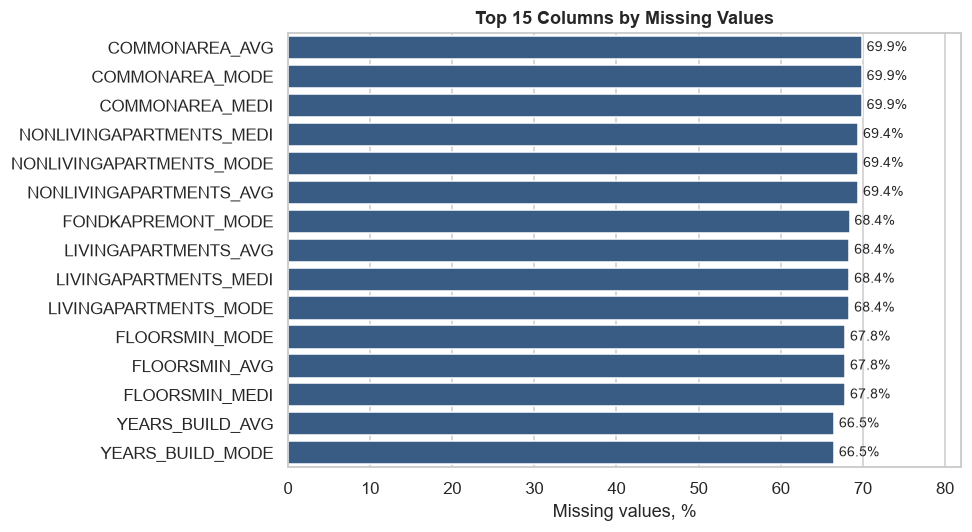

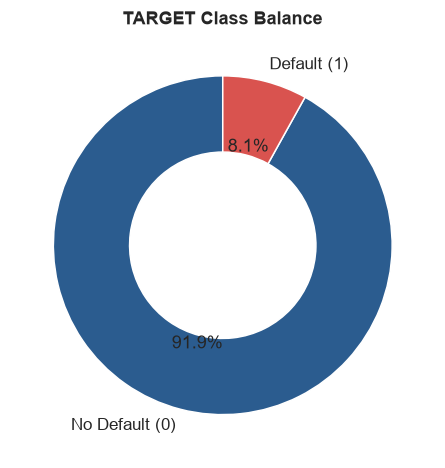

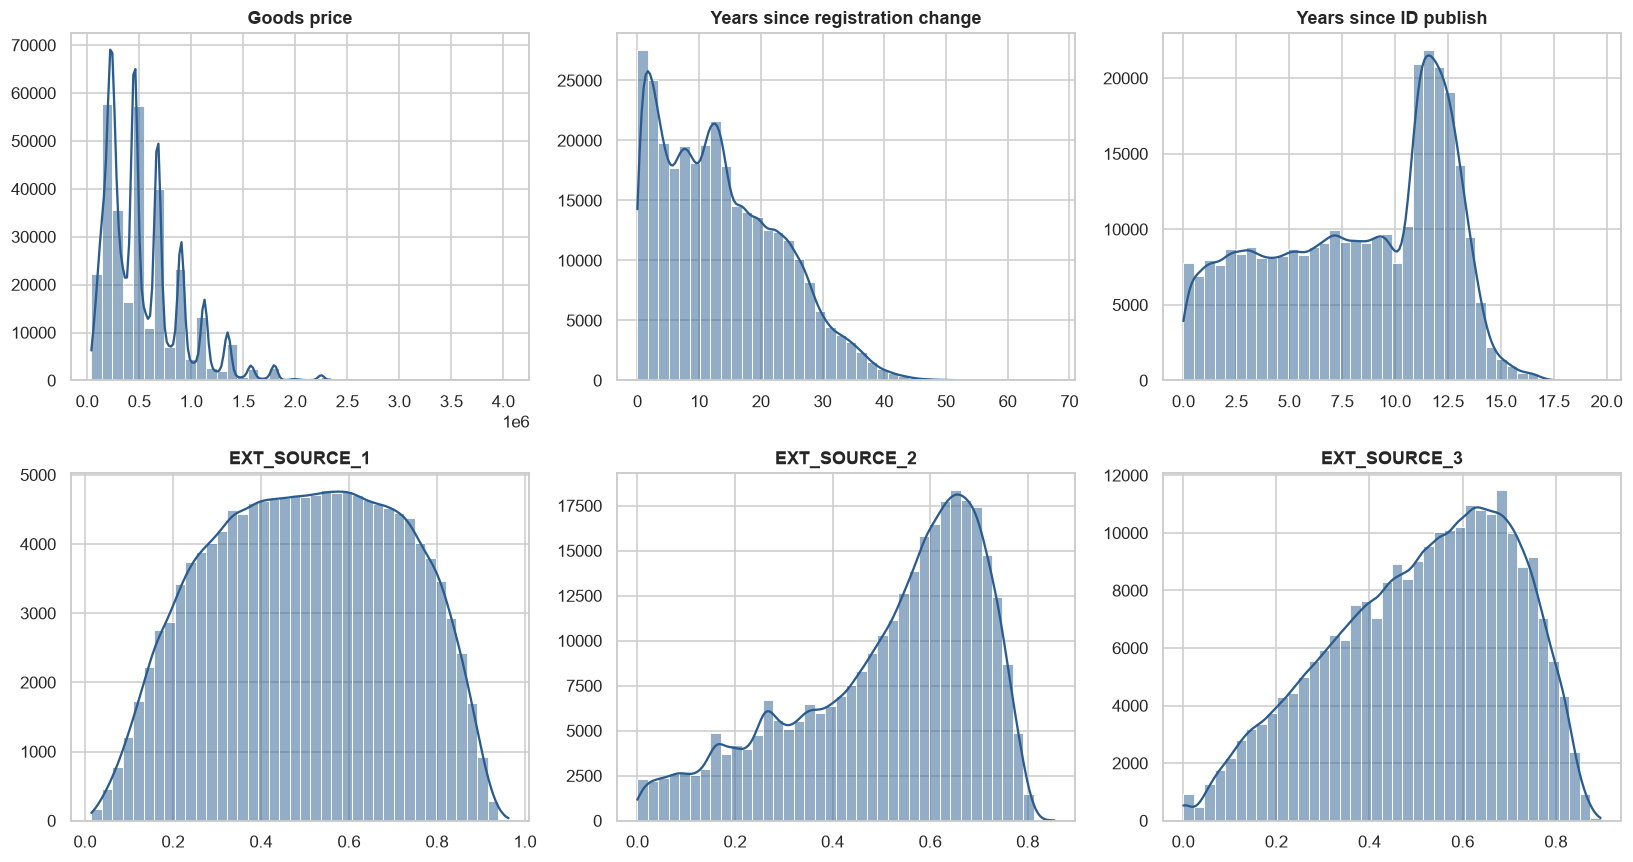

DAYS_EMPLOYED > 0: 55,374 rows (18.0%)


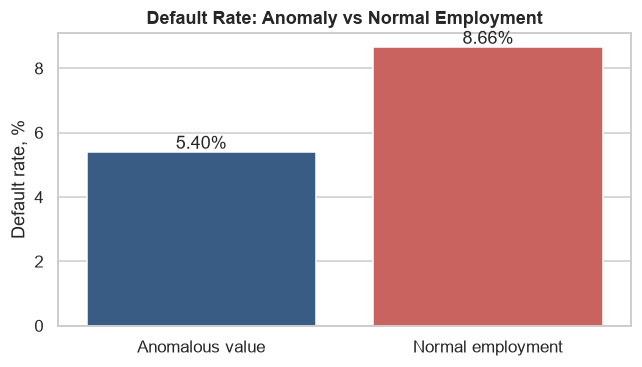

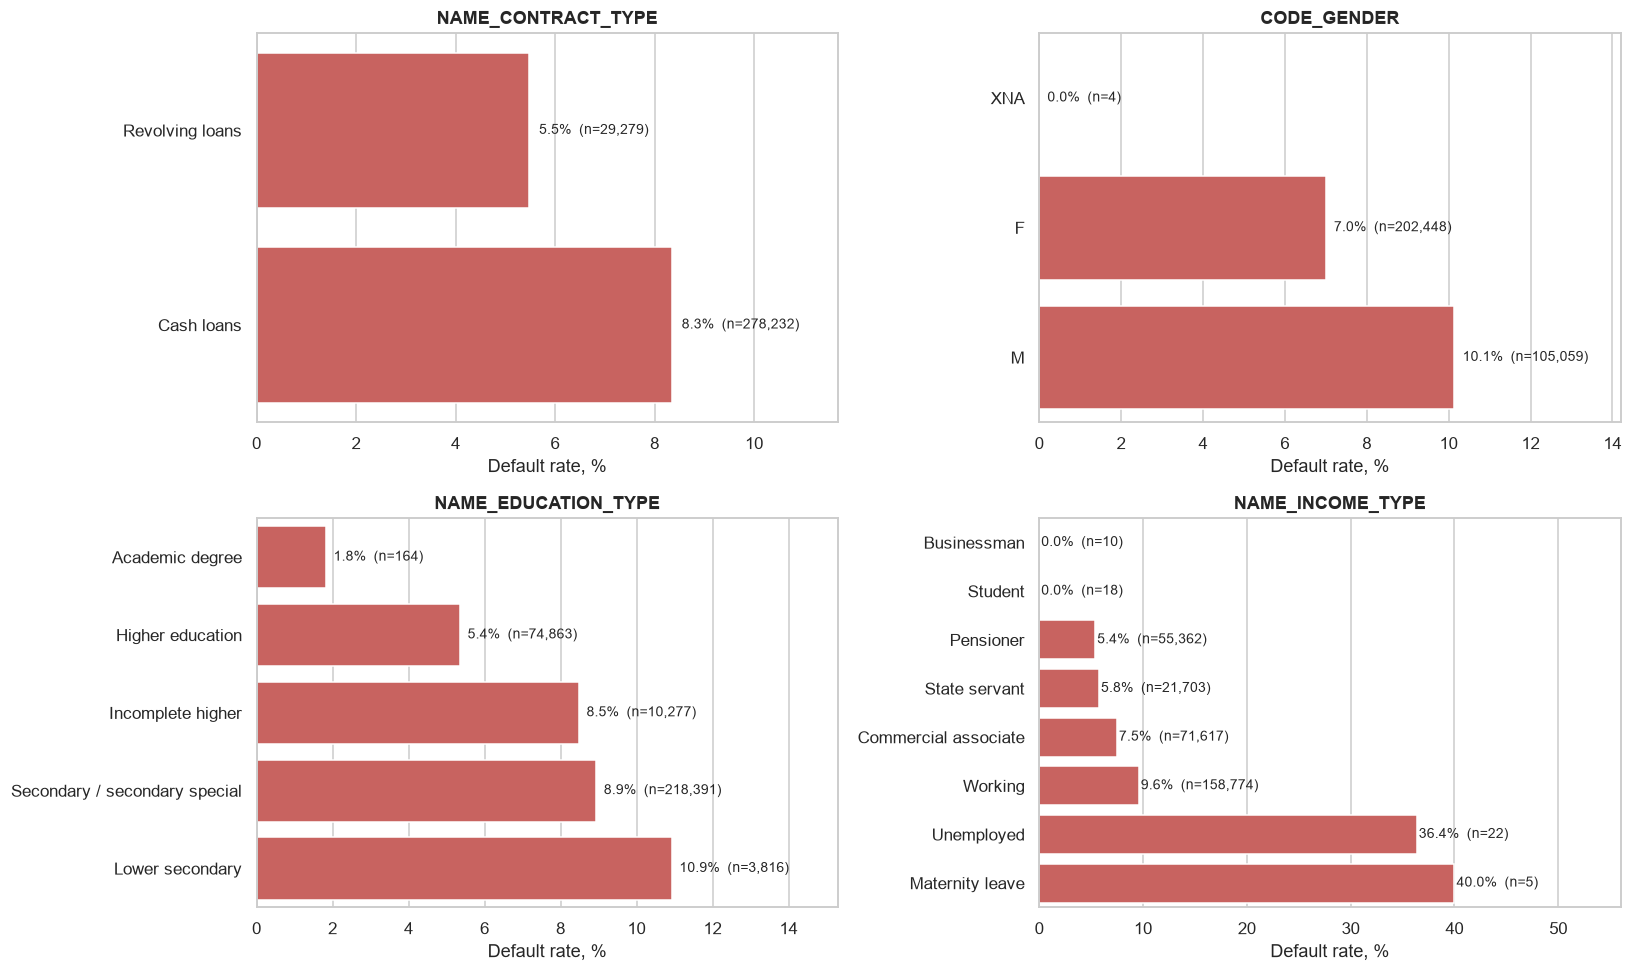

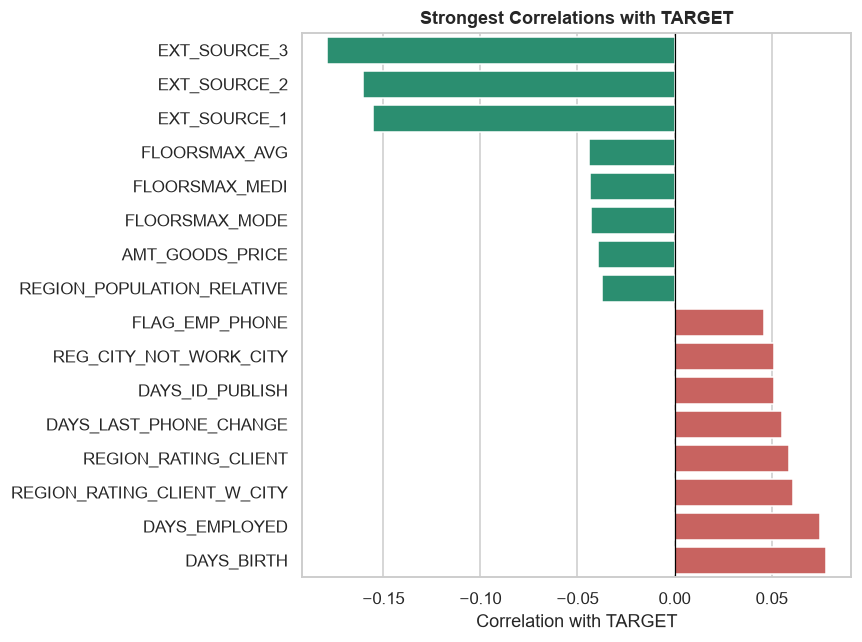

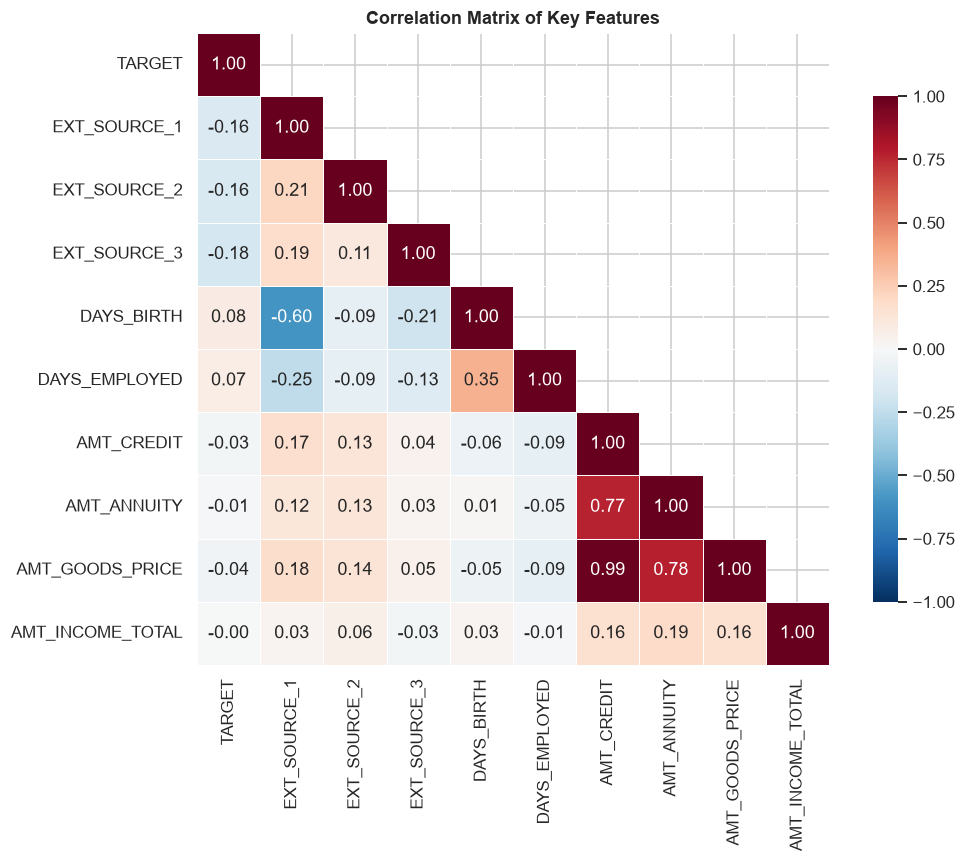

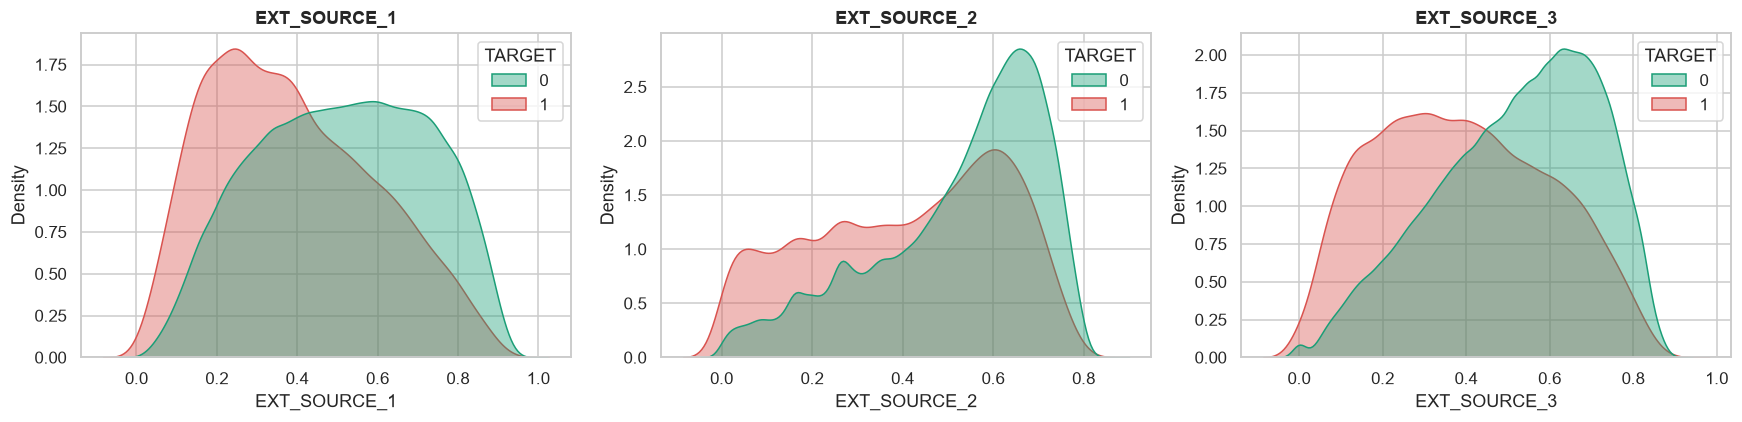

,Before,After,Change
ROC-AUC,0.7155,0.7206,0.0051
Precision (default),0.1456,0.1509,0.0053
Recall (default),0.6688,0.6497,-0.0191
F1 (default),0.2391,0.2450,0.0058
Accuracy,0.6564,0.6767,0.0203


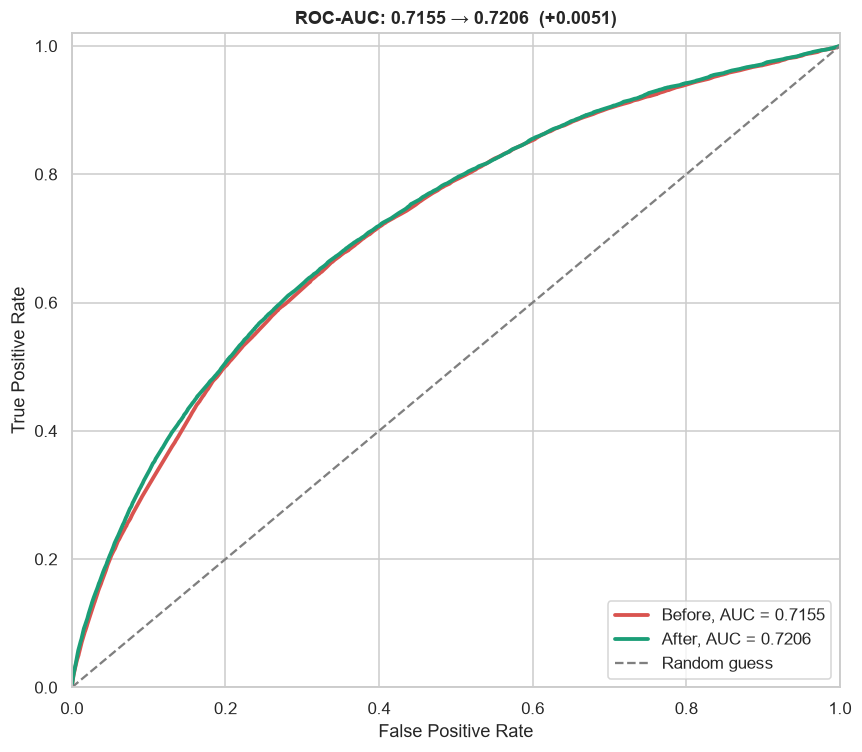

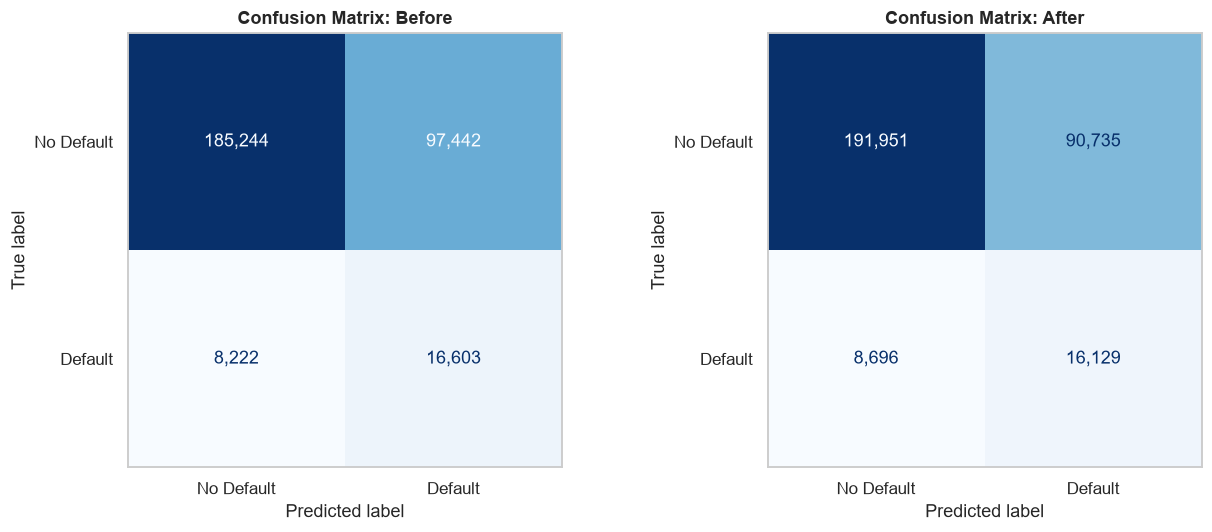

In [4]:
%matplotlib inline
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score, accuracy_score)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 12})
BLUE, RED, GREEN, GRAY = '#2b5c8f', '#d9534f', '#1b9e77', '#7f7f7f'

train_df = pd.read_csv('application_train.csv')
test_df = pd.read_csv('application_test.csv')

total_missing = int(train_df.isnull().sum().sum())
print(f"Observations (train): {train_df.shape[0]:,}")
print(f"Observations (test):  {test_df.shape[0]:,}")
print(f"Variables:            {train_df.shape[1]}")
print(f"Missing values:       {total_missing:,} ({total_missing / train_df.size * 100:.1f}% of all cells)")
print(f"Duplicates:           {train_df.duplicated().sum()}")

train_df = train_df.drop_duplicates().reset_index(drop=True)

feature_cols = train_df.columns.drop(['TARGET', 'SK_ID_CURR'])
n_num = len(train_df[feature_cols].select_dtypes(include='number').columns)
n_cat = len(train_df[feature_cols].select_dtypes(exclude='number').columns)
print(f"Numeric features:     {n_num}")
print(f"Categorical features: {n_cat}")

display(train_df.sample(5, random_state=42).iloc[:, :12])

miss_pct = (train_df.isnull().mean() * 100).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=miss_pct.values, y=miss_pct.index, orient='h', color=BLUE, ax=ax)
for i, v in enumerate(miss_pct.values):
    ax.text(v + 0.6, i, f'{v:.1f}%', va='center', fontsize=9)
ax.set_xlim(0, 82)
ax.set_xlabel('Missing values, %')
ax.set_ylabel('')
ax.set_title('Top 15 Columns by Missing Values')
plt.tight_layout()
plt.show()

tc = train_df['TARGET'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(tc.values, labels=['No Default (0)', 'Default (1)'], colors=[BLUE, RED], autopct='%1.1f%%',
       startangle=90, wedgeprops={'width': 0.45, 'edgecolor': 'white'})
ax.set_title('TARGET Class Balance')
plt.show()

dist = {
    'Goods price': train_df['AMT_GOODS_PRICE'],
    'Years since registration change': -train_df['DAYS_REGISTRATION'] / 365,
    'Years since ID publish': -train_df['DAYS_ID_PUBLISH'] / 365,
    'EXT_SOURCE_1': train_df['EXT_SOURCE_1'],
    'EXT_SOURCE_2': train_df['EXT_SOURCE_2'],
    'EXT_SOURCE_3': train_df['EXT_SOURCE_3'],
}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (title, s) in zip(axes.flatten(), dist.items()):
    sns.histplot(s.dropna(), bins=40, kde=True, color=BLUE, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

anom = train_df['DAYS_EMPLOYED'] > 0
print(f"DAYS_EMPLOYED > 0: {anom.sum():,} rows ({anom.mean() * 100:.1f}%)")
rate = train_df.groupby(anom.map({True: 'Anomalous value', False: 'Normal employment'}))['TARGET'].mean() * 100
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.barplot(x=rate.index, y=rate.values, palette=[BLUE, RED], ax=ax)
for i, v in enumerate(rate.values):
    ax.text(i, v + 0.1, f'{v:.2f}%', ha='center')
ax.set_ylabel('Default rate, %')
ax.set_xlabel('')
ax.set_title('Default Rate: Anomaly vs Normal Employment')
plt.tight_layout()
plt.show()

cat_show = ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE']
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col in zip(axes.flatten(), cat_show):
    g = train_df.groupby(col)['TARGET'].agg(['mean', 'count']).sort_values('mean')
    sns.barplot(x=g['mean'] * 100, y=g.index, orient='h', color=RED, ax=ax)
    for i, (m, n) in enumerate(zip(g['mean'], g['count'])):
        ax.text(m * 100 + 0.2, i, f'{m * 100:.1f}%  (n={n:,})', va='center', fontsize=9)
    ax.set_xlim(0, g['mean'].max() * 100 * 1.4)
    ax.set_xlabel('Default rate, %')
    ax.set_ylabel('')
    ax.set_title(col)
plt.tight_layout()
plt.show()

eda_df = train_df.copy()
eda_df.loc[eda_df['DAYS_EMPLOYED'] > 0, 'DAYS_EMPLOYED'] = np.nan

corr_t = eda_df.corr(numeric_only=True)['TARGET'].drop('TARGET').sort_values()
corr_top = pd.concat([corr_t.head(8), corr_t.tail(8)])
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=corr_top.values, y=corr_top.index, orient='h',
            palette=[GREEN if v < 0 else RED for v in corr_top.values], ax=ax)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Correlation with TARGET')
ax.set_ylabel('')
ax.set_title('Strongest Correlations with TARGET')
plt.tight_layout()
plt.show()

key_cols = ['TARGET', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
            'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'AMT_INCOME_TOTAL']
corr_matrix = eda_df[key_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.5, square=True, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Correlation Matrix of Key Features')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']):
    sns.kdeplot(data=eda_df, x=col, hue='TARGET', common_norm=False, fill=True,
                palette={0: GREEN, 1: RED}, alpha=0.4, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()


def add_features(df):
    df = df.copy()

    df['DAYS_EMPLOYED_ANOM'] = (df['DAYS_EMPLOYED'] > 0).astype(int)
    df.loc[df['DAYS_EMPLOYED'] > 0, 'DAYS_EMPLOYED'] = np.nan

    df['CREDIT_INCOME_PERCENT'] = df['AMT_CREDIT'] / (df['AMT_INCOME_TOTAL'] + 1e-5)
    df['ANNUITY_INCOME_PERCENT'] = df['AMT_ANNUITY'] / (df['AMT_INCOME_TOTAL'] + 1e-5)
    df['DAYS_EMPLOYED_PERCENT'] = df['DAYS_EMPLOYED'] / (df['DAYS_BIRTH'] - 1e-5)
    df['INCOME_PER_PERSON'] = df['AMT_INCOME_TOTAL'] / (df['CNT_FAM_MEMBERS'] + 1e-5)

    ext_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
    df['EXT_SOURCE_MEAN'] = df[ext_cols].mean(axis=1)
    df['EXT_SOURCE_MIN'] = df[ext_cols].min(axis=1)
    df['EXT_SOURCE_MAX'] = df[ext_cols].max(axis=1)

    return df.replace([np.inf, -np.inf], np.nan)

y = train_df['TARGET']
test_ids = test_df['SK_ID_CURR']
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def run_cv(Xtr, Xte):
    num_cols = Xtr.select_dtypes(include='number').columns
    cat_cols = Xtr.select_dtypes(exclude='number').columns
    prep = ColumnTransformer(transformers=[
        ('num', Pipeline(steps=[('imputer', SimpleImputer(strategy='median'))]), num_cols),
        ('cat', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), cat_cols)
    ])
    Xp = prep.fit_transform(Xtr)
    Xtp = prep.transform(Xte)

    init = DecisionTreeClassifier(max_depth=10, min_samples_leaf=100, class_weight='balanced', random_state=42)
    init.fit(Xp, y)
    idx = np.where(init.feature_importances_ > 0.001)[0]
    Xp_sel, Xtp_sel = Xp[:, idx], Xtp[:, idx]

    oof = np.zeros(len(Xtr))
    test_pred = np.zeros(len(Xte))
    for tr_i, va_i in skf.split(Xp_sel, y):
        model = DecisionTreeClassifier(max_depth=8, min_samples_leaf=100, class_weight='balanced', random_state=42)
        model.fit(Xp_sel[tr_i], y.iloc[tr_i])
        oof[va_i] = model.predict_proba(Xp_sel[va_i])[:, 1]
        test_pred += model.predict_proba(Xtp_sel)[:, 1] / skf.n_splits
    return oof, test_pred


X_base = train_df.drop(columns=['TARGET', 'SK_ID_CURR'])
X_test_base = test_df.drop(columns=['SK_ID_CURR'])
base_oof, _ = run_cv(X_base, X_test_base)

X_new = add_features(train_df).drop(columns=['TARGET', 'SK_ID_CURR'])
X_test_new = add_features(test_df).drop(columns=['SK_ID_CURR'])
new_oof, new_test_pred = run_cv(X_new, X_test_new)


def get_metrics(oof):
    pred = (oof >= 0.5).astype(int)
    return {
        'ROC-AUC': roc_auc_score(y, oof),
        'Precision (default)': precision_score(y, pred),
        'Recall (default)': recall_score(y, pred),
        'F1 (default)': f1_score(y, pred),
        'Accuracy': accuracy_score(y, pred),
    }


metrics_df = pd.DataFrame({'Before': get_metrics(base_oof), 'After': get_metrics(new_oof)})
metrics_df['Change'] = metrics_df['After'] - metrics_df['Before']
display(metrics_df.round(4))


auc_b = roc_auc_score(y, base_oof)
auc_n = roc_auc_score(y, new_oof)
fpr_b, tpr_b, _ = roc_curve(y, base_oof)
fpr_n, tpr_n, _ = roc_curve(y, new_oof)

fig, ax = plt.subplots(figsize=(8, 7))
ax.plot(fpr_b, tpr_b, color=RED, lw=2.5, label=f'Before, AUC = {auc_b:.4f}')
ax.plot(fpr_n, tpr_n, color=GREEN, lw=2.5, label=f'After, AUC = {auc_n:.4f}')
ax.plot([0, 1], [0, 1], color=GRAY, lw=1.5, linestyle='--', label='Random guess')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title(f'ROC-AUC: {auc_b:.4f} → {auc_n:.4f}  ({auc_n - auc_b:+.4f})')
ax.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, title, oof in zip(axes, ['Before', 'After'], [base_oof, new_oof]):
    cm = confusion_matrix(y, (oof >= 0.5).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=['No Default', 'Default']).plot(
        cmap='Blues', values_format=',d', ax=ax, colorbar=False)
    ax.grid(False)
    ax.set_title(f'Confusion Matrix: {title}')
plt.tight_layout()
plt.show()

submission = pd.DataFrame({'SK_ID_CURR': test_ids, 'TARGET': new_test_pred})
submission.to_csv('submission.csv', index=False)